# Snapget y1 — fine-tune YOLO11 cho xác minh ảnh Daily Quest

Model nhận diện 9 lớp vật thể của 6 quest: (bicycle, motorcycle), (keyboard, laptop), umbrella, chair, (cup, bottle), book. Mỗi lớp được gán nhãn riêng; các lớp trong ngoặc chỉ gộp lại khi chấm quest (ảnh qua nếu có bất kỳ lớp nào trong nhóm).

| Ô | Nội dung |
|---|---|
| 0 | Mount Drive, lấy code, cài thư viện | |
| 1 | COCO 2017 → dataset YOLO 9 lớp | `10` |
| 2 | Giải nén dữ liệu bổ sung | |
| 3 | Gộp dữ liệu, kiểm tra, chia tập | `11` |
| 4 | Fine-tune YOLO11s | `13` |
| 5 | Đánh giá, so sánh các model | `14` |
| 6 | Đánh giá từng lớp | `15` |
| 7 | Export ONNX, đưa model lên Hugging Face | `16` |
| 8 | Bảng tổng hợp kết quả | |


In [1]:
# 0a. Drive
from google.colab import drive
drive.mount('/content/drive')
WORK = '/content/drive/MyDrive/snapget-ml'      # dữ liệu gốc + checkpoint (Drive)
YOLO = '/content/yolo'                          # dataset làm việc (đĩa Colab)
EXT = '/content/ext'                            # dữ liệu bổ sung đã giải nén
import os
for d in [WORK, f'{WORK}/data', f'{WORK}/artifacts', YOLO, EXT]:
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive


In [4]:
# 0b. Code + thư viện
%cd /content
!rm -rf datn && git clone --depth 1 https://github.com/HuyenVt001/datn.git datn
%cd /content/datn/ml
!pip install -q -r requirements.txt
!pip install -q "pillow<13.0,>=8.0"
!nvidia-smi --query-gpu=name,memory.total --format=csv

/content
Cloning into 'datn'...
remote: Enumerating objects: 824, done.
remote: Counting objects: 100% (824/824), done.
remote: Compressing objects: 100% (733/733), done.
remote: Total 824 (delta 64), reused 448 (delta 27), pack-reused 0 (from 0)
Receiving objects: 100% (824/824), 55.72 MiB | 18.35 MiB/s, done.
Resolving deltas: 100% (64/64), done.
/content/datn/ml
name, memory.total [MiB]
NVIDIA L4, 23034 MiB


## 1. COCO 2017 → YOLO 9 lớp
- Lấy ảnh COCO có chứa 9 lớp (tối đa 2.000 ảnh/lớp) cùng 1.500 ảnh nền không có lớp nào, giữ nguyên box gốc.
- Bổ sung khoảng 20% bản cắt dọc 3:4 mô phỏng ảnh chụp điện thoại. Tập test lấy từ COCO val2017.
- Tải và nén  thành `coco_yolo9.zip`

In [6]:
import os
ZIP = f'{WORK}/data/coco_yolo9.zip'
if os.path.exists(ZIP):
    !unzip -q -o {ZIP} -d {YOLO}
else:
    !python scripts/10_export_coco_yolo.py --out {YOLO}/coco --max-per-class 2000 --negatives 1500 \
        --test-max 3000 --test-negatives 500 --portrait-frac 0.2
    !cd {YOLO} && zip -q -r {ZIP} coco
!head -40 {YOLO}/coco/stats.json

/usr/local/lib/python3.13/dist-packages/glob2/fnmatch.py:141: SyntaxWarning: invalid escape sequence '\Z'
  return '(?ms)' + res + '\Z'

Extracting annotations to '/root/fiftyone/coco-2017/raw/instances_train2017.json'

Writing annotations for 2000 downloaded samples to '/root/fiftyone/coco-2017/train/labels.json'
Dataset info written to '/root/fiftyone/coco-2017/info.json'
Loading 'coco-2017' split 'train'

Dataset 'y1-coco-train-cup-42-2000' created
[train] cup: 2000 anh (2000 co 'cup') -> tong 2000
Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017.json'
668 images found; downloading the remaining 1332

Writing annotations for 3332 downloaded samples to '/root/fiftyone/coco-2017/train/labels.json'
Dataset info written to '/root/fiftyone/coco-2017/info.json'
Loading 'coco-2017' split 'train'

Dataset 'y1-coco-train-bottle-42-2000' created
[train] bottle: 2000 anh (2000 co 'bottle') -> tong 3332
Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017

## 2. Dữ liệu bổ sung
COCO chủ yếu là ảnh nước ngoài, thiếu nhiều vật thể quen thuộc ở Việt Nam nên nhóm đã xây dựng một bộ dữ liệu bổ sung :
- `snapget_vn_supplement.zip` — tập train bổ sung dữ liệu bản địa: ảnh bối cảnh Việt Nam, nhãn YOLO 9 lớp, chỉ dùng để train.
- `vn.zip` — ảnh tự chụp bằng điện thoại, gồm `train/` và `test/` (cấu trúc theo `ml/DATASET_SPEC.md`). Tập test chỉ gồm ảnh tự chụp; đây là tập dùng để chọn ngưỡng và đánh giá. Khi chưa có, ngưỡng tạm chọn trên tập val.

Hai file đã được lọc còn 9 lớp và bổ sung ảnh bằng notebook `snapget_vn_data.ipynb`.

In [7]:
import os
# ảnh tự chụp (train + test)
!rm -rf {EXT}/vn
if os.path.exists(f'{WORK}/data/vn.zip'):
    print('vn.zip: có')
    !mkdir -p {EXT}/vn && unzip -q -o "{WORK}/data/vn.zip" -d {EXT}/vn
else:
    print('vn.zip: chưa có -> không có tập test ảnh thật, ngưỡng chọn tạm trên val')
# tập train bổ sung dữ liệu bản địa
!rm -rf {EXT}/snapget_vn_supplement
if os.path.exists(f'{WORK}/data/snapget_vn_supplement.zip'):
    print('snapget_vn_supplement.zip: có')
    !unzip -q -o {WORK}/data/snapget_vn_supplement.zip -d {EXT}
else:
    print('snapget_vn_supplement.zip: KHÔNG TÌM THẤY trong WORK/data/')
!ls {EXT}

vn.zip: có
snapget_vn_supplement.zip: có
snapget_vn_supplement  vn


## 3. Gộp dữ liệu, kiểm tra, chia tập
Gộp COCO với dữ liệu bổ sung thành `data.yaml` và danh sách ảnh cho từng tập:
- ảnh bổ sung được lặp ×3 trong tập train để không bị COCO lấn át;
- ảnh test tự chụp chia 40% `real_calib` (chọn ngưỡng) / 60% `real_test` (báo cáo);
- ảnh train gần trùng ảnh test (dHash) bị loại để tránh rò rỉ.

In [8]:
import glob, os

def find_vn(base):
    # file nén có thể bọc thêm 1–2 tầng thư mục
    cands = [p.rstrip('/') for p in glob.glob(f'{base}/**/', recursive=True)
             if os.path.isdir(os.path.join(p, 'train', 'images')) or os.path.isdir(os.path.join(p, 'test', 'images'))]
    return sorted(cands, key=len)[0] if cands else None

VN_DIR = find_vn(f'{EXT}/vn')
vn = f'--vn {VN_DIR}' if VN_DIR else ''
if os.path.isdir(f'{EXT}/snapget_vn_supplement/train'):
    vn += f' --vn {EXT}/snapget_vn_supplement'
VN_MIN_TRAIN = 100   # số ảnh Việt Nam tối thiểu mỗi lớp trong train
!python scripts/11_merge_external.py --root {YOLO} --coco {YOLO}/coco {vn} --class-map yolo_class_map.yaml \
    --vn-min-train {VN_MIN_TRAIN}
!cp {YOLO}/merge_report.json {WORK}/artifacts/merge_report.json

  ⚠ VN vn: lop 'potted plant' da bo khoi model -> bo box lop nay (nen loc truoc bang 18_prepare_vn_data.py)
  ⚠ VN vn: lop 'backpack' da bo khoi model -> bo box lop nay (nen loc truoc bang 18_prepare_vn_data.py)
  ⚠ VN vn: lop 'clock' da bo khoi model -> bo box lop nay (nen loc truoc bang 18_prepare_vn_data.py)
  ⚠ VN train: ten file 'gg_backpack_0001.jpg' co ten lop khong thuoc 9 lop (lop co dau cach dung '_', vd ten lop da bo)
  ⚠ VN train: ten file 'gg_backpack_0002.jpg' co ten lop khong thuoc 9 lop (lop co dau cach dung '_', vd ten lop da bo)
  ⚠ VN train: gg_backpack_0002.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: ten file 'gg_backpack_0003.jpg' co ten lop khong thuoc 9 lop (lop co dau cach dung '_', vd ten lop da bo)
  ⚠ VN train: gg_backpack_0003.jpg khong co box nao nhung ten khong phai neg/hardneg — kiem tra lai
  ⚠ VN train: ten file 'gg_backpack_0004.jpg' co ten lop khong thuoc 9 lop (lop co dau cach dung '_', vd ten lop da bo)
  ⚠ VN 

## 4. Fine-tune
- Khởi tạo từ YOLO11s pretrained COCO; head 80 lớp được cắt còn 9 lớp.
- `imgsz 640`, 40 epoch; dừng sớm nếu 12 epoch liền không cải thiện; 8 epoch cuối tắt mosaic.
- Khi bị Colab ngắt thì chạy lại ô 0 → 1 → 2 → 3 rồi chạy 4b.

In [9]:
# 4a. Train YOLO11s
!python scripts/13_train_yolo.py --data {YOLO}/data.yaml --model yolo11s.pt \
    --project {WORK}/artifacts/yolo --name y2-s --epochs 40 --export-best {WORK}/artifacts/y2-s/best.pt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Khoi tao tu head COCO da cat 9 lop -> /content/drive/MyDrive/snapget-ml/artifacts/yolo/_init/yolo11s-coco9.pt
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=No

In [10]:
# 4b. Train tiếp từ checkpoint sau khi Colab ngắt
!python scripts/13_train_yolo.py --data {YOLO}/data.yaml --project {WORK}/artifacts/yolo --name y2-s --resume \
    --export-best {WORK}/artifacts/y2-s/best.pt

Resume tu /content/drive/MyDrive/snapget-ml/artifacts/yolo/y2-s/weights/last.pt
WARNING ⚠️ model '/content/drive/MyDrive/snapget-ml/artifacts/yolo/y2-s/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, f

## 5. Đánh giá
Các model được đánh giá trên cùng tập ảnh và cùng cách chọn ngưỡng:
- `yolo11s-coco` — YOLO11s gốc chưa fine-tune (mốc so sánh);
- `y1-s` — model 12 lớp cũ, chỉ so điểm cấp ảnh trên 9 lớp (không chạy detection);
- `y2-s` — model 9 lớp vừa fine-tune.

Hai cấp chỉ số:
- **Detection:** mAP50, mAP50-95 từng lớp, confusion matrix 10×10 (9 lớp + nền).
- **Xác minh ảnh** (đúng với quyết định của app): AP, precision, recall, F1, tỉ lệ từ chối sai, confusion cấp ảnh.

Ngưỡng từng lớp được chọn trên `real_calib` theo nguyên tắc recall cao nhất với precision ≥ 0.80. Đo thêm độ trễ suy luận trên CPU.

In [11]:
import os

def find_weights(name):
    # best.pt sau khi train xong; chưa xong thì lấy best.pt của lượt train đang dở
    for p in (f'{WORK}/artifacts/{name}/best.pt', f'{WORK}/artifacts/yolo/{name}/weights/best.pt'):
        if os.path.exists(p):
            print(f'{name}: {p}' + ('' if p.endswith(f'{name}/best.pt') else '  (chưa train xong)'))
            return p
    print(f'{name}: chưa có -> bỏ qua')

models = '--model yolo11s-coco=yolo11s.pt'
for name in ('y1-s', 'y2-s'):
    w = find_weights(name)
    if w:
        models += f' --model {name}={w}'
meta = f'--vn-meta {VN_DIR}/metadata.csv' if VN_DIR and os.path.exists(f'{VN_DIR}/metadata.csv') else ''
!python scripts/14_eval_yolo.py --root {YOLO} --out {WORK}/artifacts/eval {models} {meta} --max-coco 2000

y1-s: /content/drive/MyDrive/snapget-ml/artifacts/y1-s/best.pt
y2-s: /content/drive/MyDrive/snapget-ml/artifacts/y2-s/best.pt
calib (real_calib) 287 anh | real_test 431 | coco_test 1581

===== yolo11s-coco (yolo: yolo11s.pt) =====
nguong: {'cup': 0.2122, 'bottle': 0.705, 'book': 0.3771, 'chair': 0.7578, 'laptop': 0.1513, 'keyboard': 0.1817, 'umbrella': 0.0918, 'bicycle': 0.1408, 'motorcycle': 0.6776}
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s summary (fused): 100 layers, 9,416,283 parameters, 3,483 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3473.2±721.3 MB/s, size: 207.0 KB)
val: Scanning /content/yolo/vn/labels/test... 431 images, 136 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 431/431 1.7Kit/s 0.3s
val: New cache created: /content/yolo/vn/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 7.0it/s 3.8s
                   all    

Tập: real_test
/content/drive/MyDrive/snapget-ml/artifacts/eval/y2-s/det_real_test/confusion_matrix_normalized.png


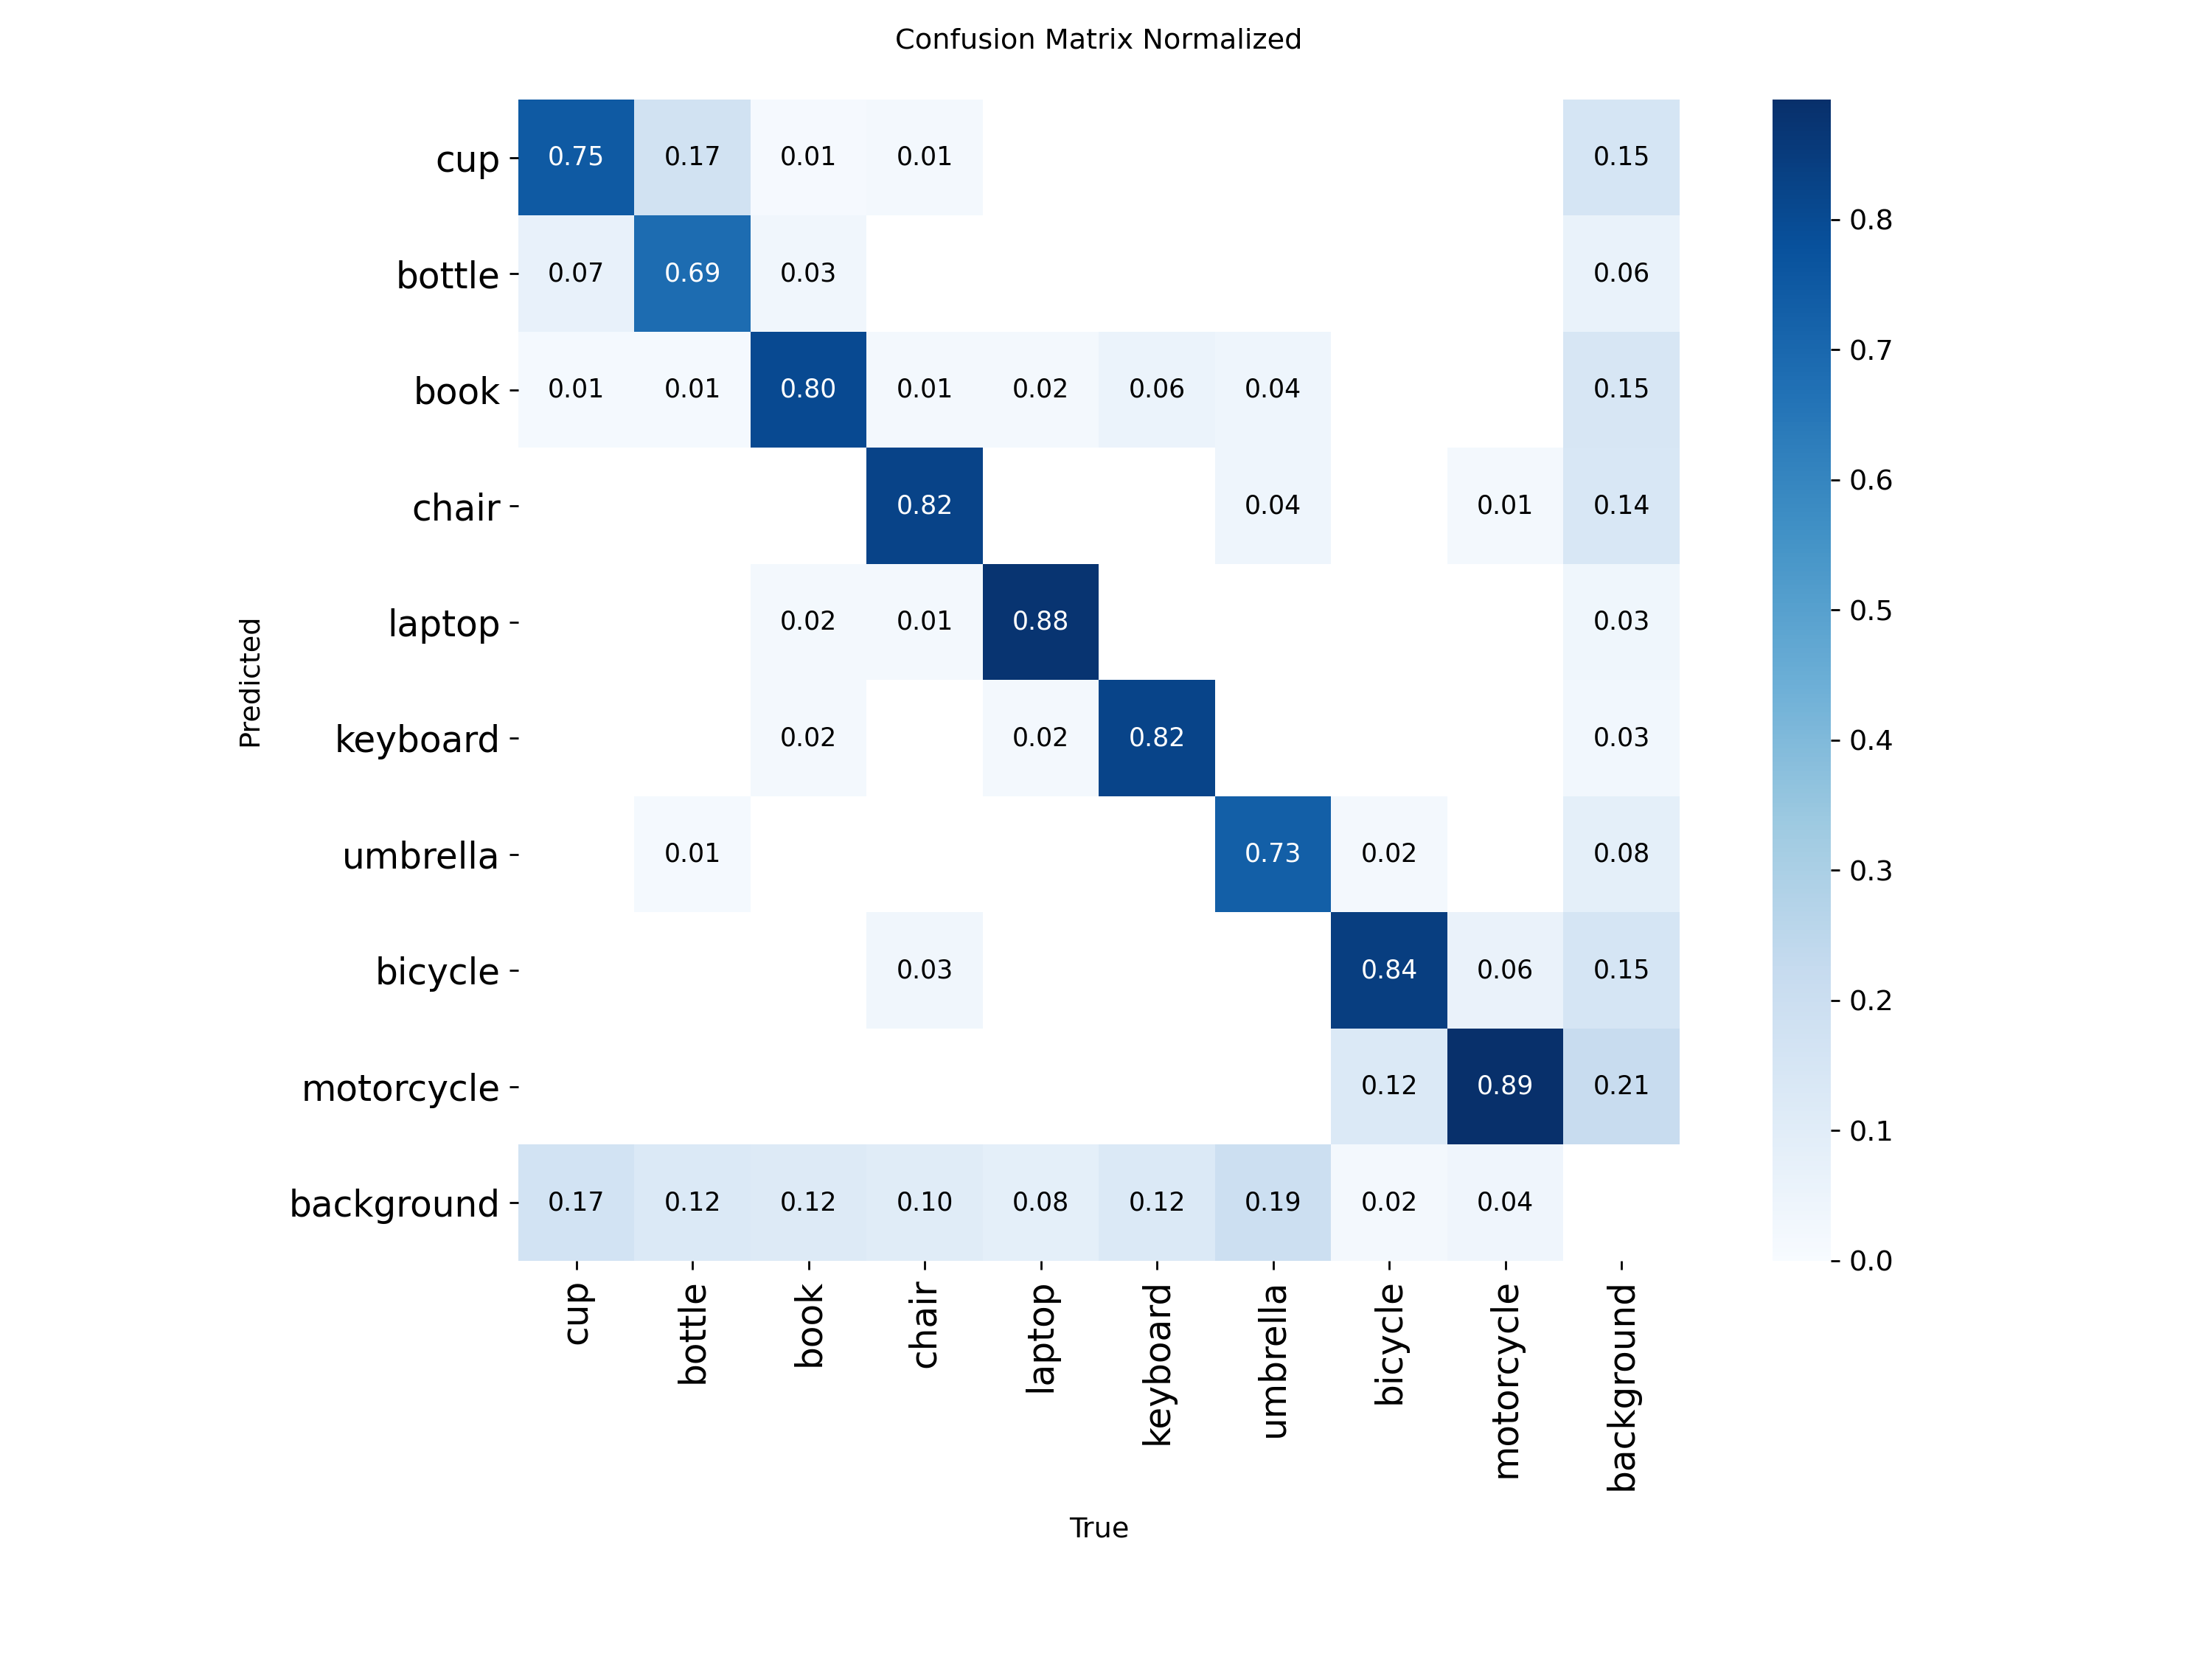

/content/drive/MyDrive/snapget-ml/artifacts/eval/y2-s/image_confusion_real_test.png


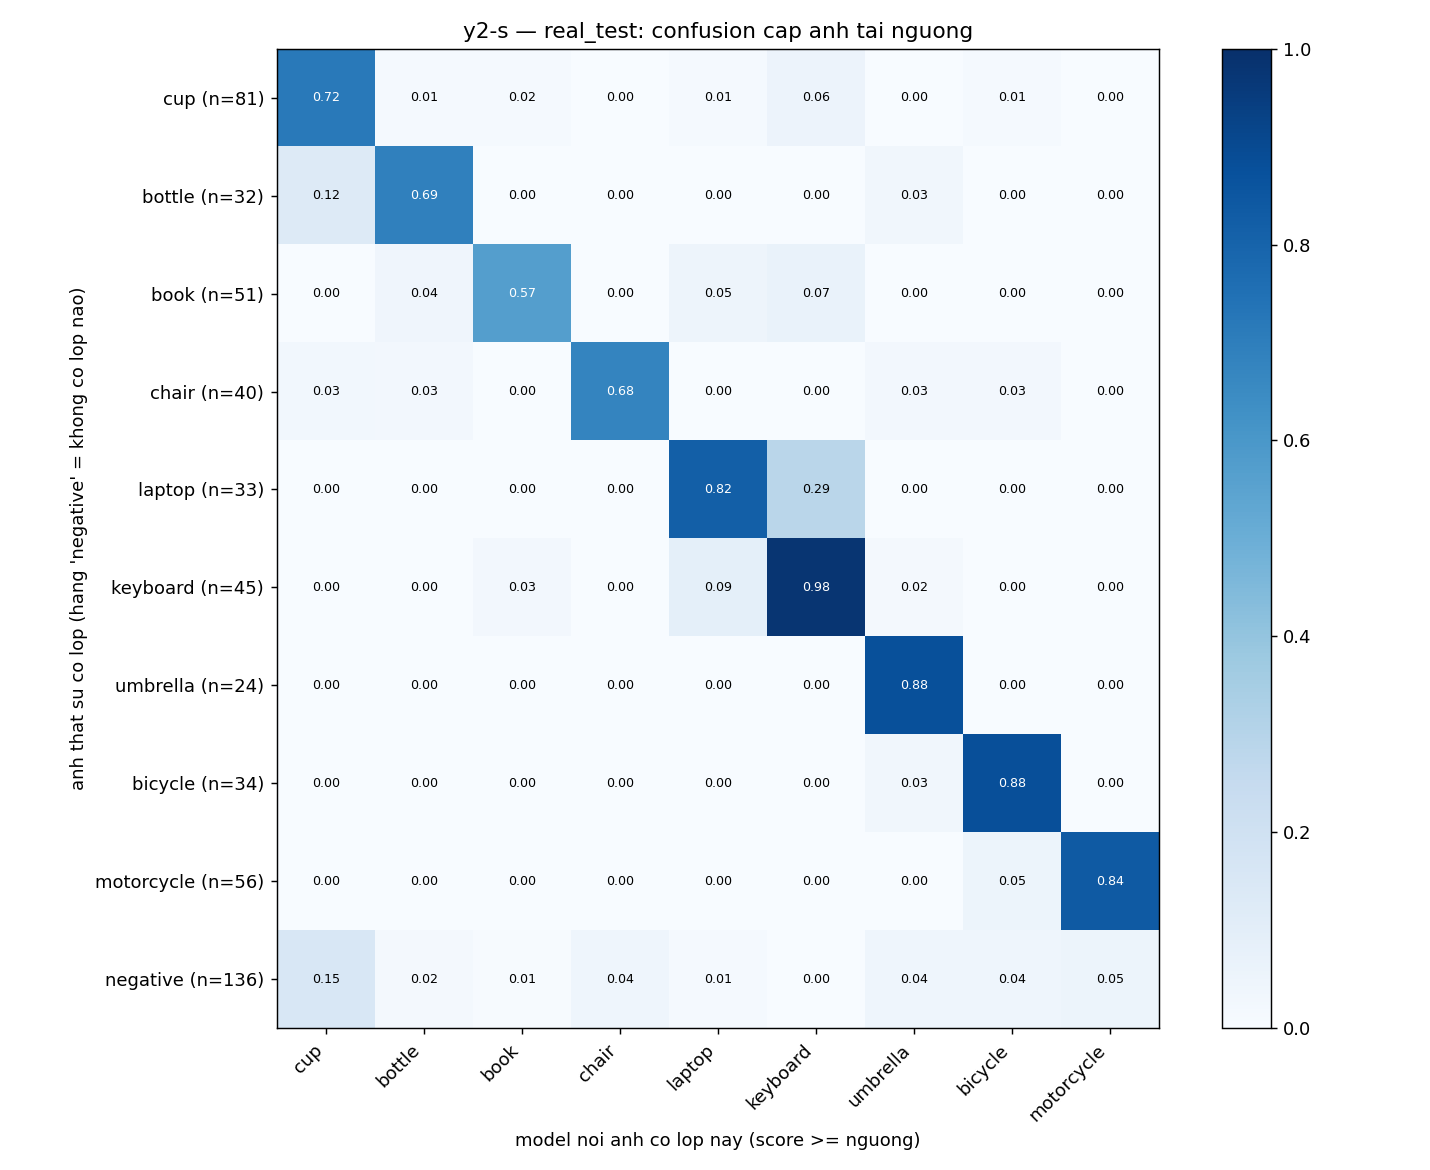

/content/drive/MyDrive/snapget-ml/artifacts/eval/y2-s/pr_curves_real_test.png


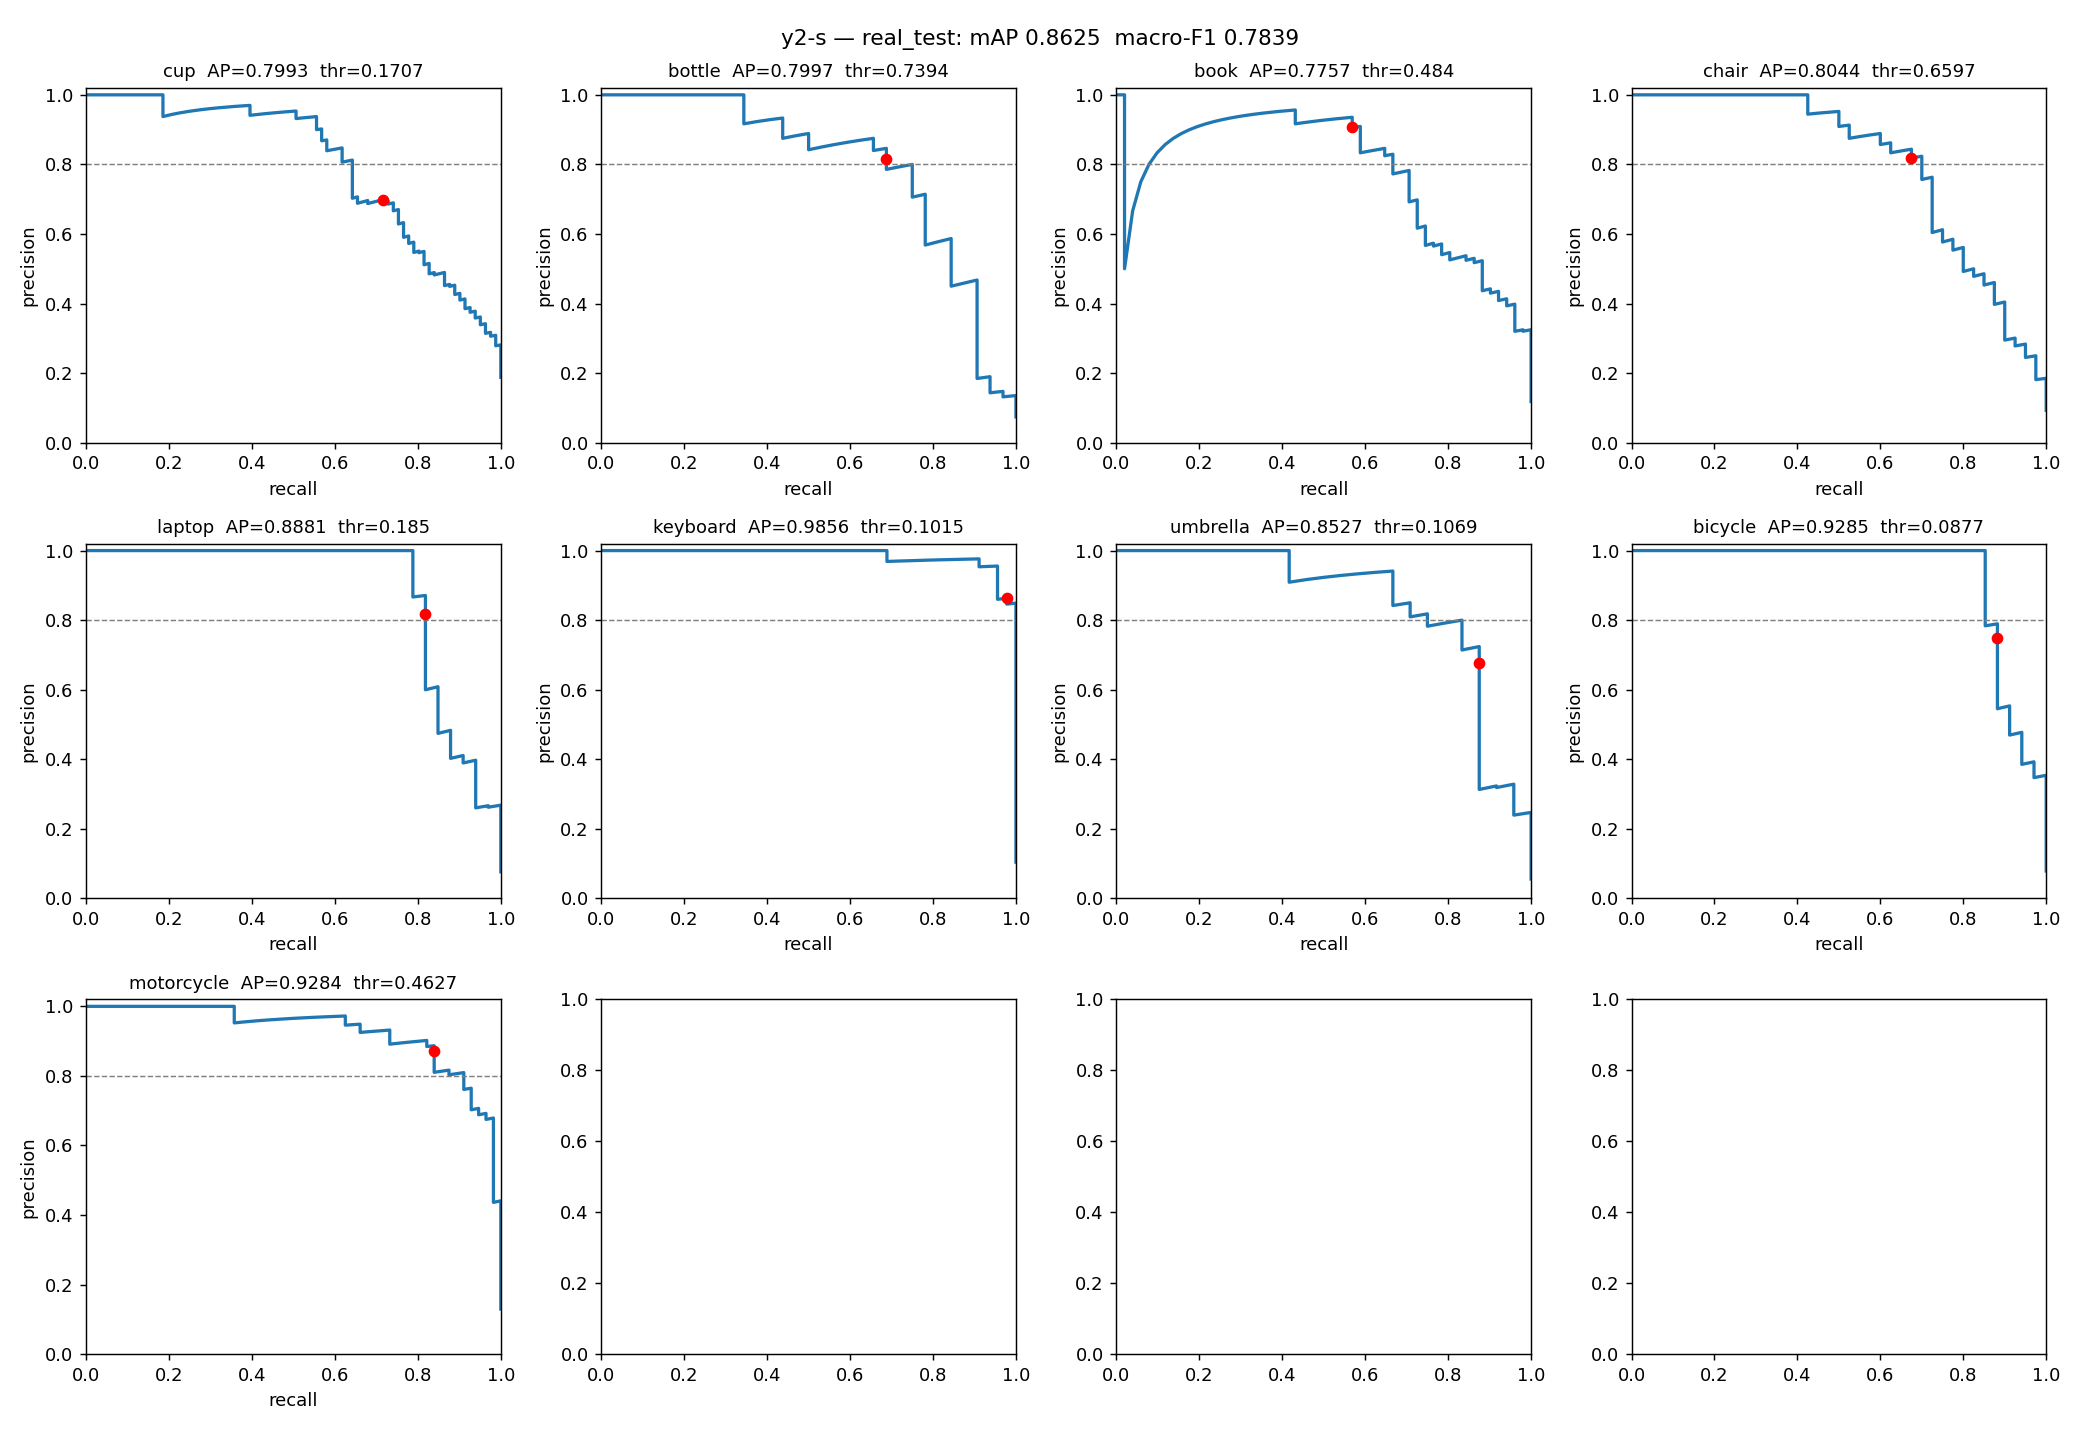

/content/drive/MyDrive/snapget-ml/artifacts/eval/y2-s/det_real_test/BoxF1_curve.png


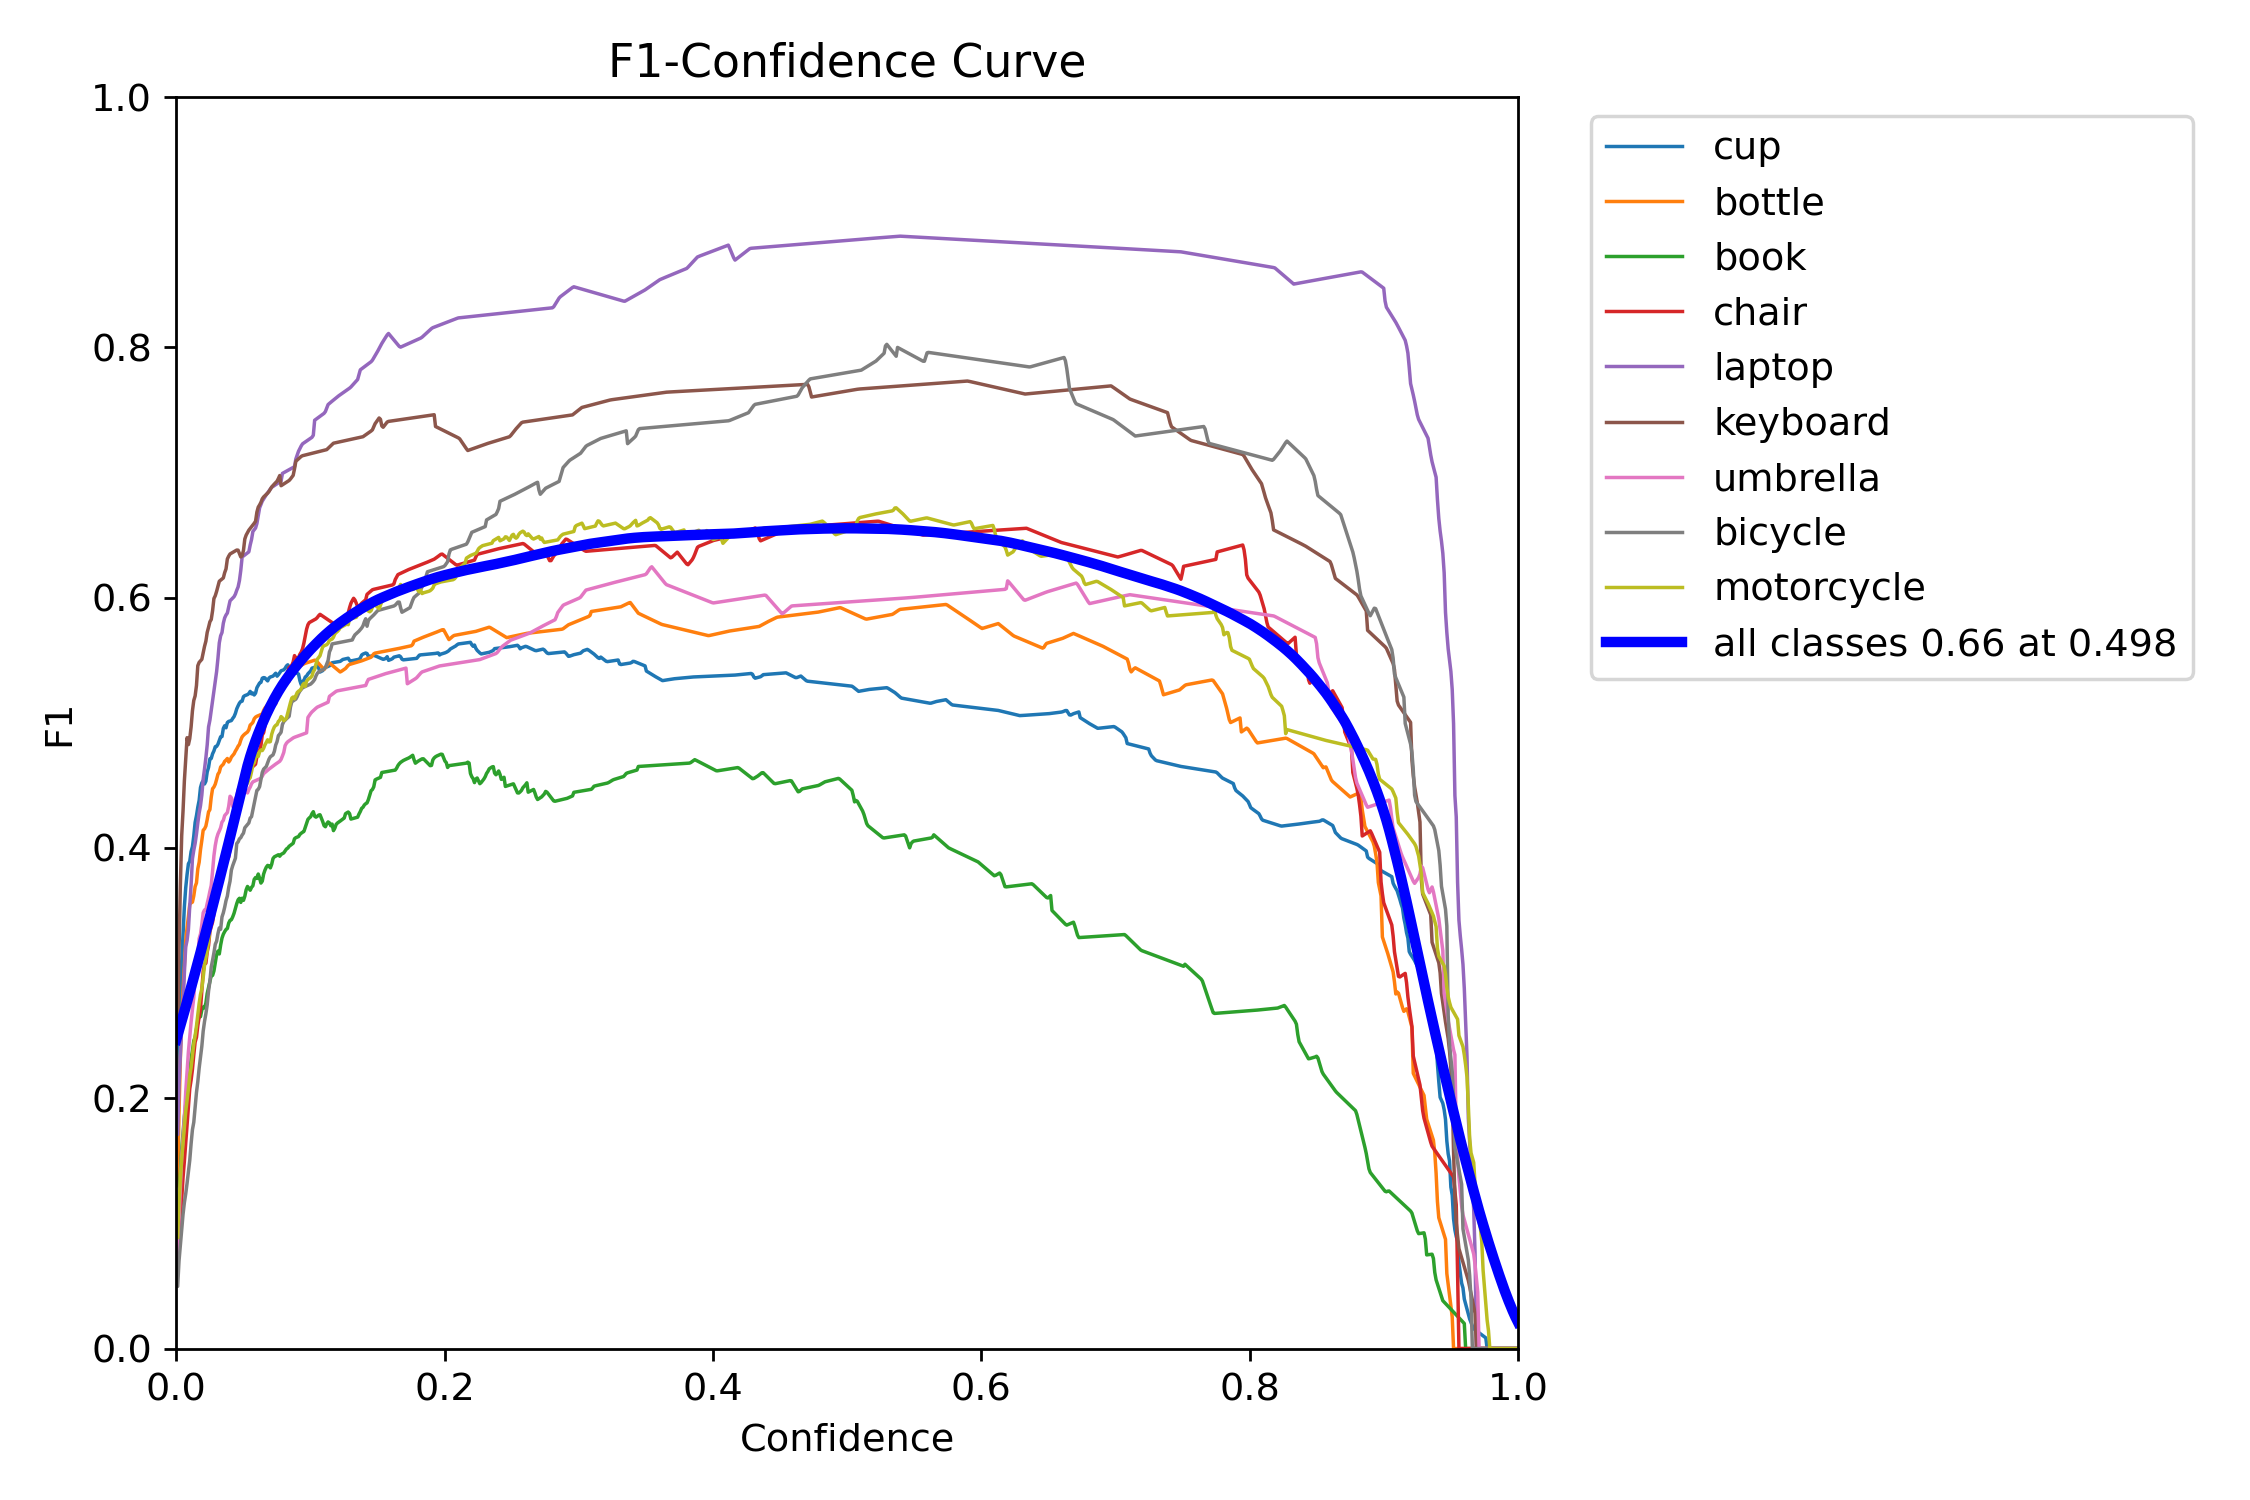

In [12]:
# Biểu đồ của y2-s: confusion matrix (detection), confusion cấp ảnh, PR curve, F1 curve
# (real_test nếu đã có ảnh tự chụp, không thì coco_test)
from IPython.display import Image, display
import os
EVAL = f'{WORK}/artifacts/eval/y2-s'
SPLIT = 'real_test' if os.path.exists(f'{EVAL}/metrics_real_test.json') else 'coco_test'
print('Tập:', SPLIT)
for p in [f'{EVAL}/det_{SPLIT}/confusion_matrix_normalized.png',
          f'{EVAL}/image_confusion_{SPLIT}.png',
          f'{EVAL}/pr_curves_{SPLIT}.png',
          f'{EVAL}/det_{SPLIT}/BoxF1_curve.png']:
    if os.path.exists(p):
        print(p); display(Image(p, width=900))

## 6. Đánh giá từng lớp
Bảng chỉ số của `y2-s` trên `real_test` cho từng lớp: AP cấp ảnh, F1 / precision / recall tại ngưỡng, tỉ lệ từ chối sai, AP50 và AP50-95 detection, lớp hay bị nhận nhầm.

Đánh giá theo quest (gộp nhóm) nằm ở notebook `snapget_quest_eval.ipynb`.

In [13]:
import os
EVAL = f'{WORK}/artifacts/eval/y2-s'
SPLIT = 'real_test' if os.path.exists(f'{EVAL}/metrics_real_test.json') else 'coco_test'
if SPLIT != 'real_test':
    print('Chưa có real_test -> kết quả dưới đây là tạm thời (trên coco_test)')
!python scripts/15_eval_report.py --eval {EVAL} --split {SPLIT}

# Đánh giá từng lớp — model `y2-s`, tập `real_test` (ngưỡng chọn trên `real_calib`)

| Lớp | Ảnh test | Ngưỡng | AP ảnh | F1 | P | R | Từ chối sai | AP50 box | AP50-95 box | Bị nhận nhầm từ | Hay bị nhận thành |
|---|---|---|---|---|---|---|---|---|---|---|---|
| cup | 81 | 0.171 | 0.799 | 0.707 | 0.699 | 0.716 | 28% | 0.533 | 0.434 | negative (15%) | keyboard (6%) |
| bottle | 32 | 0.739 | 0.800 | 0.746 | 0.815 | 0.688 | 31% | 0.531 | 0.492 | book (4%) | cup (12%) |
| book | 51 | 0.484 | 0.776 | 0.699 | 0.906 | 0.569 | 43% | 0.430 | 0.315 | keyboard (3%) | keyboard (7%) |
| chair | 40 | 0.660 | 0.804 | 0.740 | 0.818 | 0.675 | 32% | 0.640 | 0.527 | negative (4%) | cup (3%) |
| laptop | 33 | 0.185 | 0.888 | 0.818 | 0.818 | 0.818 | 18% | 0.867 | 0.812 | keyboard (9%) | keyboard (29%) |
| keyboard | 45 | 0.102 | 0.986 | 0.917 | 0.863 | 0.978 | 2% | 0.740 | 0.629 | laptop (29%) | laptop (9%) |
| umbrella | 24 | 0.107 | 0.853 | 0.764 | 0.677 | 0.875 | 12% | 0.531 | 0.439 | negative (4%) | –

## 7. Export ONNX và triển khai
Export ONNX fp32 (không lượng tử hoá int8 vì làm giảm độ chính xác), so khớp đầu ra với PyTorch, rồi tải `model.onnx`, `thresholds.json`, `model_meta.json` lên Hugging Face. AI service trên Cloud Run tải model từ đó khi khởi động; sau khi restart, `/health` trả về `modelVersion: "y2"`, `arch: "yolo"`.

In [14]:
from huggingface_hub import login
login()
MODEL_REPO = 'Flowerng/snapget-ai-model'
!python scripts/16_export_yolo_onnx.py --weights {WORK}/artifacts/y2-s/best.pt \
    --thresholds {WORK}/artifacts/eval/y2-s/thresholds.json --version y2 --out {WORK}/artifacts/y2-s/export \
    --upload {MODEL_REPO}

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
WARNING ⚠️ This model has no one-to-one head; using one-to-many outputs.
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,416,283 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/snapget-ml/artifacts/y2-s/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 13, 8400) (18.3 MB)

ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.2s, saved as '/content/drive/MyDrive/snapget-ml/artifacts/y2-s/best.onnx' (36.2 MB)

Export complete (2.6s)
Results saved to /content/drive/MyDrive/snapget-ml/artifacts/y2-s/best.onnx
Predict:         yolo predict task=detect model=/content/d

## 8. Tổng hợp
So sánh các model trên từng tập: mAP cấp ảnh, macro-F1, mAP50 / mAP50-95 detection và độ trễ trung vị trên CPU.

In [15]:
import json
rows = json.load(open(f'{WORK}/artifacts/eval/ablation.json'))
f = lambda v: '-' if v is None else (f'{v:.3f}' if isinstance(v, float) else str(v))
print(f"{'model':14s} {'split':10s} {'n':>5s} {'mAP ảnh':>8s} {'macroF1':>8s} {'AP50 box':>9s} {'AP50-95':>8s} {'p50 ms':>7s}")
for r in rows:
    print(f"{r['model']:14s} {r['split']:10s} {r['n']:5d} {f(r['imageMAP']):>8s} {f(r['macroF1']):>8s} "
          f"{f(r['detMAP50']):>9s} {f(r['detMAP50_95']):>8s} {f(r['latencyP50ms']):>7s}")

model          split          n  mAP ảnh  macroF1  AP50 box  AP50-95  p50 ms
yolo11s-coco   real_test    431    0.854    0.737     0.627    0.542       -
yolo11s-coco   coco_test   1581    0.897    0.725     0.623    0.430       -
y1-s           real_test    431    0.868    0.775         -        -       -
y1-s           coco_test   1581    0.867    0.668         -        -       -
y2-s           real_test    431    0.863    0.784     0.641    0.539       -
y2-s           coco_test   1581    0.861    0.693     0.580    0.393       -
